In [2]:
import sys, os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import mlflow
import mlflow.lightgbm
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import PrecisionRecallDisplay

from src.preprocessing.sort_and_split import load_raw_data, sort_by_time, time_split
from src.preprocessing.missing_values import encode_m_columns, fill_nan_for_trees

print('Imports OK')

Imports OK


In [3]:
# ── MLflow setup ──────────────────────────────────────────────────────────────
mlflow.set_tracking_uri('http://127.0.0.1:5000')
mlflow.set_experiment('01_Baseline')
print('MLflow tracking URI:', mlflow.get_tracking_uri())

2026/06/11 16:02:57 INFO mlflow.tracking.fluent: Experiment with name '01_Baseline' does not exist. Creating a new experiment.


MLflow tracking URI: http://localhost:5000


In [10]:
import sys, os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())


In [ ]:
# ── Load raw data ─────────────────────────────────────────────────────────────
train_df, test_df = load_raw_data('data/raw')
print(f'Train: {train_df.shape}  Test: {test_df.shape}')
print(f'Fraud rate: {train_df["isFraud"].mean():.3%}')  

2026-06-11 16:07:01.623 | INFO     | src.preprocessing.sort_and_split:load_raw_data:33 - Loading raw CSVs from data\raw
2026-06-11 16:08:41.747 | INFO     | src.preprocessing.sort_and_split:load_raw_data:43 - Train shape: (590540, 434)  |  Test shape: (506691, 433)


Train: (590540, 434)  Test: (506691, 433)
Fraud rate: 3.499%


In [12]:
# ── Minimal preprocessing (Rules 1 + 2 only) ──────────────────────────────────
# Rule 1: Sort
train_df = sort_by_time(train_df)

# Rule 2: M column encode + fill -999
train_df = encode_m_columns(train_df, nan_value=-1)
train_df = fill_nan_for_trees(train_df, exclude_cols=['isFraud'])

# Time split
train_split, val_split = time_split(train_df, train_quantile=0.75)
print(f'Train: {len(train_split)}  Val: {len(val_split)}')

2026-06-11 16:10:37.671 | INFO     | src.preprocessing.sort_and_split:sort_by_time:64 - Sorted by TransactionDT.  Day range: 1 – 182  |  Hour distribution: 13.9±7.6
2026-06-11 16:10:39.618 | INFO     | src.preprocessing.missing_values:encode_m_columns:47 - Encoded 9 M-columns (NaN → -1).  Sample: {'M1': np.int64(1), 'M2': np.int64(1), 'M3': np.int64(1)}
2026-06-11 16:10:52.811 | INFO     | src.preprocessing.missing_values:fill_nan_for_trees:85 - Tree NaN fill (-999): 104178894 NaN values filled across 413 numeric columns.
2026-06-11 16:11:00.420 | INFO     | src.preprocessing.sort_and_split:time_split:94 - Time split at day 130 (q=0.75).  Train: 445173 rows (15630 fraud)  |  Val: 145367 rows (5033 fraud)


Train: 445173  Val: 145367


In [13]:
# ── Feature columns (numeric only, drop strings and IDs) ─────────────────────
EXCLUDE = ['TransactionID', 'TransactionDT', 'isFraud',
           'card4', 'card6', 'ProductCD', 'DeviceType',
           'P_emaildomain', 'R_emaildomain', 'DeviceInfo',
           'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28',
           'id_29', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36',
           'id_37', 'id_38']

feature_cols = [
    c for c in train_split.columns
    if c not in EXCLUDE and train_split[c].dtype != object
]

print(f'Feature columns: {len(feature_cols)}')
print('Sample:', feature_cols[:10])

Feature columns: 411
Sample: ['TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'dist1', 'dist2', 'C1']


In [14]:
# ── Baseline LightGBM params (no HPO) ─────────────────────────────────────────
BASELINE_PARAMS = {
    'n_estimators':     1000,
    'num_leaves':       127,
    'learning_rate':    0.05,
    'subsample':        0.8,
    'colsample_bytree': 0.8,
    'min_child_samples':20,
    'scale_pos_weight': 27,
    'metric':           'average_precision',
    'objective':        'binary',
    'random_state':     42,
    'verbose':         -1,
    'n_jobs':          -1,
}

X_train = train_split[feature_cols].values
y_train = train_split['isFraud'].values
X_val   = val_split[feature_cols].values
y_val   = val_split['isFraud'].values

In [15]:
# ── Train with MLflow logging ─────────────────────────────────────────────────
with mlflow.start_run(run_name='lgbm_baseline_no_fe') as run:

    # Log all hyperparameters
    mlflow.log_params(BASELINE_PARAMS)
    mlflow.log_params({
        'n_features':      len(feature_cols),
        'train_samples':   len(X_train),
        'val_samples':     len(X_val),
        'fraud_rate':      float(y_train.mean()),
        'feature_engineering': 'none',
        'preprocessing':   'sort+M_encode+fill_-999',
        'model_type':      'LightGBM',
    })

    # Train
    model = lgb.LGBMClassifier(**BASELINE_PARAMS)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[
            lgb.early_stopping(100, verbose=False),
            lgb.log_evaluation(200),
        ]
    )

    # Predict
    val_preds = model.predict_proba(X_val)[:, 1]

    # Compute metrics
    val_auc  = roc_auc_score(y_val, val_preds)
    val_aupr = average_precision_score(y_val, val_preds)

    # Log metrics
    mlflow.log_metrics({
        'val_auc_roc':         val_auc,
        'val_auc_pr':          val_aupr,
        'best_iteration':      model.best_iteration_,
    })

    print(f'\n{"="*50}')
    print(f'Exp 1 BASELINE Results')
    print(f'  Val AUC-ROC : {val_auc:.5f}')
    print(f'  Val AUC-PR  : {val_aupr:.5f}')
    print(f'  Best iter   : {model.best_iteration_}')
    print(f'{"="*50}')

    print(f'\nMLflow Run ID: {run.info.run_id}')
    RUN_ID_EXP1 = run.info.run_id

[200]	valid_0's average_precision: 0.525699
[400]	valid_0's average_precision: 0.536925
[600]	valid_0's average_precision: 0.543554
[800]	valid_0's average_precision: 0.548659

Exp 1 BASELINE Results
  Val AUC-ROC : 0.90001
  Val AUC-PR  : 0.54964
  Best iter   : 829

MLflow Run ID: b7e0d5c53359434a849d1688cd4886ec
🏃 View run lgbm_baseline_no_fe at: http://localhost:5000/#/experiments/1/runs/b7e0d5c53359434a849d1688cd4886ec
🧪 View experiment at: http://localhost:5000/#/experiments/1


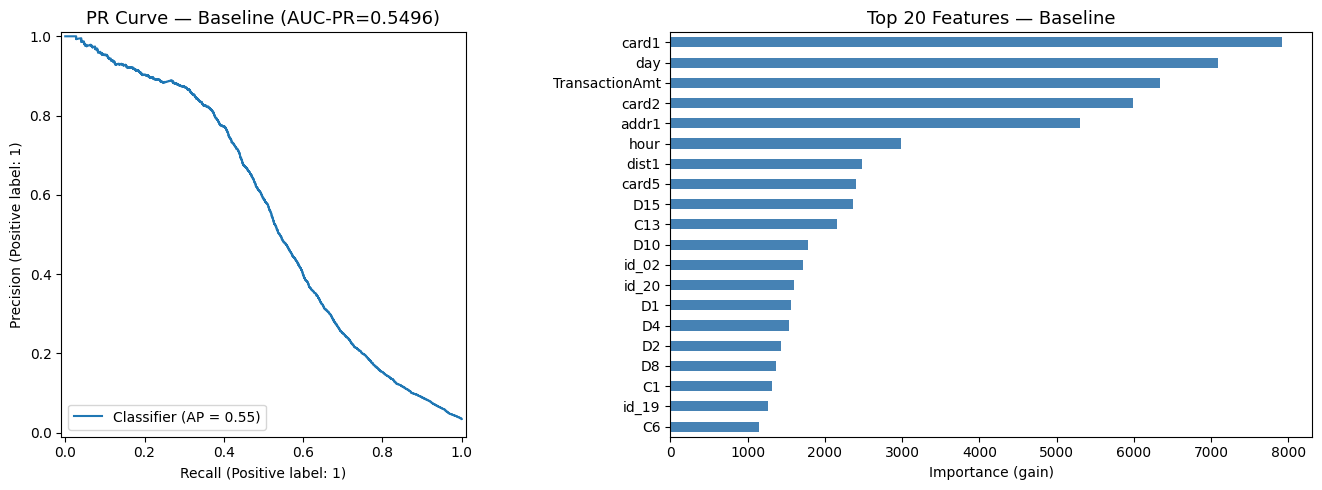

🏃 View run lgbm_baseline_no_fe at: http://localhost:5000/#/experiments/1/runs/b7e0d5c53359434a849d1688cd4886ec
🧪 View experiment at: http://localhost:5000/#/experiments/1


In [16]:
# ── Precision-Recall curve ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# PR Curve
PrecisionRecallDisplay.from_predictions(y_val, val_preds, ax=axes[0])
axes[0].set_title(f'PR Curve — Baseline (AUC-PR={val_aupr:.4f})', fontsize=13)

# Feature Importance (top 20)
importance = pd.Series(model.feature_importances_, index=feature_cols)
importance.nlargest(20).sort_values().plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Top 20 Features — Baseline', fontsize=13)
axes[1].set_xlabel('Importance (gain)')

plt.tight_layout()
os.makedirs('artifacts/shap', exist_ok=True)
plt.savefig('artifacts/shap/exp01_baseline_pr_importance.png', dpi=150, bbox_inches='tight')
plt.show()

# Log plot to MLflow
with mlflow.start_run(run_id=RUN_ID_EXP1):
    mlflow.log_artifact('artifacts/shap/exp01_baseline_pr_importance.png')

In [17]:
# ── Save metrics JSON (DVC will track this) ────────────────────────────────────
os.makedirs('artifacts/metrics', exist_ok=True)
metrics = {
    'experiment':  '01_baseline',
    'n_features':  len(feature_cols),
    'val_auc_roc': round(val_auc,  5),
    'val_auc_pr':  round(val_aupr, 5),
    'model':       'LightGBM',
    'feature_engineering': 'none',
}
with open('artifacts/metrics/exp01_baseline.json', 'w') as f:
    json.dump(metrics, f, indent=2)

print('Metrics saved. Run the next notebook: 02_feature_engineering.ipynb')
print(f'Baseline AUC-PR: {val_aupr:.5f} ← this is the floor to beat')

Metrics saved. Run the next notebook: 02_feature_engineering.ipynb
Baseline AUC-PR: 0.54964 ← this is the floor to beat
